In [51]:
%pip install -q pandas numpy scikit-learn xgboost rdkit xlrd openpyxl matplotlib seaborn joblib

Note: you may need to restart the kernel to use updated packages.


In [68]:
import os
from pathlib import Path
import re
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    explained_variance_score
)
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator

def generate_morgan_features(df, drug1_col="drugname1", drug2_col="drugname2", radius=2, n_bits=512):
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits)
    records = []
    for _, row in df.iterrows():
        values = []
        for column in (drug1_col, drug2_col):
            molecule = Chem.MolFromSmiles(str(row[column]))
            if molecule is None:
                raise ValueError(f"Invalid SMILES in {column}: {row[column]}")
            array = np.zeros(n_bits, dtype=np.uint8)
            DataStructs.ConvertToNumpyArray(generator.GetFingerprint(molecule), array)
            values.extend(array.tolist())
        records.append(values)
    columns = [f"drug{drug}_bit_{bit}" for drug in (1, 2) for bit in range(n_bits)]
    return pd.DataFrame(records, columns=columns, index=df.index)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET_COLUMN = "score"

# Resolve processed tables from the repository root.
REPO_ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "datasets" / "processed").is_dir()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Could not locate the repository root containing datasets/processed.")
PROCESSED_DIR = REPO_ROOT / "datasets" / "processed"
DATASET_FILES = {
    "DrugComb": PROCESSED_DIR / "DrugComb_LINCS_PRISM_final_without_last_score.zip",
    "DrugCombDB": PROCESSED_DIR / "DrugCombDBLINCS_PRISM_final_without_last_score.csv",
    "Oneil": PROCESSED_DIR / "OneilLINCS_PRISM_final_without_last_score.csv",
    "ALMANAC": PROCESSED_DIR / "almanac_final_without_last_score.xls",
    "OncologyScreen": PROCESSED_DIR / "OncologyScreenLINCS_PRISM_final_without_last_score.xls"
}

# Core columns used to create drug/cell-line features.
DRUG1_COL = "drugname1"
DRUG2_COL = "drugname2"
CELLLINE_COL = "cellline"

# Add any columns here that must never be used as predictors
# (e.g. IDs, raw response labels, alternate synergy scores, or target-derived values).
EXCLUDE_FEATURE_COLUMNS = [
    # "combination_id",
    # "sample_id",
    # "bliss_score",
    # "loewe_score",
    # "zip_score",
    # "hsa_score",
]

OUTPUT_DIR = "drs_xgboost_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Configuration ready.")
print("Datasets:", list(DATASET_FILES.keys()))

Configuration ready.
Datasets: ['DrugComb', 'DrugCombDB', 'Oneil', 'ALMANAC', 'OncologyScreen']


In [69]:
def load_table(path):
    path = Path(path)
    try:
        return pd.read_csv(path, low_memory=False)
    except (UnicodeDecodeError, pd.errors.ParserError):
        return pd.read_excel(path)

def normalize_column_name(name):
    name = str(name).strip().lower()
    name = re.sub(r"[^a-z0-9]+", "_", name)
    return name.strip("_")

ALIASES = {
    "drugname1": ["drug1", "drug_name_1", "drug_name1", "compound1", "compound_1"],
    "drugname2": ["drug2", "drug_name_2", "drug_name2", "compound2", "compound_2"],
    "cellline": ["cell_line", "cell_line_name", "cell"],
    "score": ["synergy_score", "response_score", "target", "y"]
}

def standardize_columns(df):
    df = df.copy()
    df.columns = [normalize_column_name(c) for c in df.columns]
    rename = {}
    for canonical, aliases in ALIASES.items():
        if canonical not in df.columns:
            for alias in aliases:
                alias = normalize_column_name(alias)
                if alias in df.columns:
                    rename[alias] = canonical
                    break
    return df.rename(columns=rename)

loaded_data = {}

for dataset_name, path in DATASET_FILES.items():
    if not path.exists():
        print(f"[MISSING] {dataset_name}: {path}")
        continue
    try:
        df = standardize_columns(load_table(path))
        loaded_data[dataset_name] = df
        print(f"\n{'='*70}\n{dataset_name}: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
        
    except Exception as exc:
        print(f"[ERROR] Could not load {dataset_name}: {exc}")

if not loaded_data:
    raise FileNotFoundError(
        "No datasets were loaded. Check that the processed files exist under datasets/processed."
    )


DrugComb: 17,139 rows x 334 columns

DrugCombDB: 17,139 rows x 334 columns

Oneil: 2,714 rows x 334 columns

ALMANAC: 29,251 rows x 334 columns

OncologyScreen: 1,160 rows x 334 columns


## 2. Identify DRS-added feature columns

All columns other than the two drug names, cell line, target, and explicitly excluded columns are treated as candidate DRS-added features. Numeric columns are used as numeric predictors; text/category columns are one-hot encoded.

This is intentionally data-driven because the feature names can differ between source datasets.

In [70]:
CORE_COLUMNS = {DRUG1_COL, DRUG2_COL, CELLLINE_COL, TARGET_COLUMN}
EXCLUDED_NORMALIZED = {normalize_column_name(c) for c in EXCLUDE_FEATURE_COLUMNS}

feature_report = []
for name, df in loaded_data.items():
    missing_core = CORE_COLUMNS.difference(df.columns)
    if missing_core:
        print(f"{name}: missing required columns {sorted(missing_core)}")
        continue

    candidates = [
        c for c in df.columns
        if c not in CORE_COLUMNS and c not in EXCLUDED_NORMALIZED
    ]
    numeric = df[candidates].select_dtypes(include=[np.number, "bool"]).columns.tolist()
    categorical = [c for c in candidates if c not in numeric]

    feature_report.append({
        "Dataset": name,
        "Rows": len(df),
        "Candidate DRS columns": len(candidates),
        "Numeric DRS columns": len(numeric),
        "Categorical DRS columns": len(categorical),
        "DRS feature names": ", ".join(candidates)
    })

feature_report_df = pd.DataFrame(feature_report)
display(feature_report_df)

,Dataset,Rows,Candidate DRS columns,Numeric DRS columns,Categorical DRS columns,DRS feature names
0,DrugComb,17139,330,330,0,"drs_feature_1, drs_feature_2, drs_feature_3, d..."
1,DrugCombDB,17139,330,330,0,"drs_feature_1, drs_feature_2, drs_feature_3, d..."
2,Oneil,2714,330,330,0,"drs_feature_1, drs_feature_2, drs_feature_3, d..."
3,ALMANAC,29251,330,330,0,"drs_feature_1, drs_feature_2, drs_feature_3, d..."
4,OncologyScreen,1160,330,330,0,"drs_feature_1, drs_feature_2, drs_feature_3, d..."


In [71]:
def make_one_hot_encoder():
    # Compatibility with older and newer scikit-learn releases.
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=True)

def train_one_dataset(dataset_name, raw_df):
    df = raw_df.copy()

    required = [DRUG1_COL, DRUG2_COL, CELLLINE_COL, TARGET_COLUMN]
    missing = [c for c in required if c not in df.columns]
    if missing:
        print(f"[SKIP] {dataset_name}: missing required columns {missing}")
        return None

    df[TARGET_COLUMN] = pd.to_numeric(df[TARGET_COLUMN], errors="coerce")
    df = df.dropna(subset=required).drop_duplicates().copy()
    df = df.replace([np.inf, -np.inf], np.nan)
    df = df.dropna(subset=[TARGET_COLUMN])

    if len(df) < 10:
        print(f"[SKIP] {dataset_name}: only {len(df)} valid rows; need at least 10.")
        return None

    # Candidate DRS columns: everything except core identifiers/target and exclusions.
    drs_cols = [
        c for c in df.columns
        if c not in CORE_COLUMNS and c not in EXCLUDED_NORMALIZED
    ]

    # Drop columns that contain no usable information.
    drs_cols = [c for c in drs_cols if not df[c].isna().all()]

    # Generate Morgan fingerprints using the same helper as the baseline notebook.
    fingerprints = generate_morgan_features(
        df,
        drug1_col=DRUG1_COL,
        drug2_col=DRUG2_COL,
        radius=2,
        n_bits=512
    ).reset_index(drop=True)

    # Add cell line and the additional DRS features.
    extra_features = df[drs_cols].reset_index(drop=True).copy()
    extra_features[CELLLINE_COL] = df[CELLLINE_COL].astype(str).reset_index(drop=True)
    X = pd.concat([fingerprints, extra_features], axis=1)
    y = df[TARGET_COLUMN].astype(float).reset_index(drop=True)

    # Detect numeric and categorical columns after combining all features.
    categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()
    numeric_cols = [c for c in X.columns if c not in categorical_cols]

    numeric_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ])
    categorical_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("onehot", make_one_hot_encoder())
    ])

    transformers = []
    if numeric_cols:
        transformers.append(("numeric", numeric_pipe, numeric_cols))
    if categorical_cols:
        transformers.append(("categorical", categorical_pipe, categorical_cols))

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("xgb", XGBRegressor(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)
    evs = explained_variance_score(y_test, predictions)

    pearson = pd.Series(y_test).corr(pd.Series(predictions), method="pearson")
    spearman = pd.Series(y_test).corr(pd.Series(predictions), method="spearman")

    metrics = {
        "Dataset": dataset_name,
        "Rows": len(df),
        "Train rows": len(X_train),
        "Test rows": len(X_test),
        "DRS feature columns": len(drs_cols),
        "Total model input columns before encoding": X.shape[1],
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "Explained Variance": evs,
        "Pearson": pearson,
        "Spearman": spearman
    }

    # Save fitted pipeline and test predictions for later analysis.
    model_path = os.path.join(OUTPUT_DIR, f"{dataset_name}_drs_xgboost.joblib")
    joblib.dump(model, model_path)

    pred_df = pd.DataFrame({
        "actual_score": y_test.to_numpy(),
        "predicted_score": predictions
    })
    pred_df.to_csv(
        os.path.join(OUTPUT_DIR, f"{dataset_name}_test_predictions.csv"),
        index=False
    )

    print(
        f"{dataset_name}: rows={len(df)}, DRS columns={len(drs_cols)}, "
        f"MAE={mae:.4f}, RMSE={rmse:.4f}, R2={r2:.4f}"
    )

    return metrics

all_results = []
for dataset_name, dataset_df in loaded_data.items():
    print("\n" + "=" * 72)
    print("DRS-ENHANCED MODEL:", dataset_name)
    print("=" * 72)
    result = train_one_dataset(dataset_name, dataset_df)
    if result is not None:
        all_results.append(result)

results = pd.DataFrame(all_results)
if results.empty:
    raise RuntimeError(
        "No models were trained. Check the required column names, target column, "
        "dataset paths, and Morgan fingerprint helper."
    )

results.to_csv(
    os.path.join(OUTPUT_DIR, "drs_xgboost_dataset_metrics.csv"),
    index=False
)
display(results.round(4))
print("Saved metrics to:", os.path.join(OUTPUT_DIR, "drs_xgboost_dataset_metrics.csv"))


DRS-ENHANCED MODEL: DrugComb
DrugComb: rows=17139, DRS columns=330, MAE=3.0678, RMSE=4.3361, R2=0.3483

DRS-ENHANCED MODEL: DrugCombDB
DrugCombDB: rows=17139, DRS columns=330, MAE=3.0678, RMSE=4.3361, R2=0.3483

DRS-ENHANCED MODEL: Oneil
Oneil: rows=2714, DRS columns=330, MAE=11.0260, RMSE=15.1699, R2=0.5405

DRS-ENHANCED MODEL: ALMANAC
ALMANAC: rows=29251, DRS columns=330, MAE=31.9093, RMSE=43.0353, R2=0.4062

DRS-ENHANCED MODEL: OncologyScreen
OncologyScreen: rows=1160, DRS columns=330, MAE=12.1058, RMSE=17.7017, R2=0.4596


,Dataset,Rows,Train rows,Test rows,DRS feature columns,Total model input columns before encoding,MAE,RMSE,R2,Explained Variance,Pearson,Spearman
0,DrugComb,17139,13711,3428,330,1355,3.0678,4.3361,0.3483,0.3496,0.0175,-0.0171
1,DrugCombDB,17139,13711,3428,330,1355,3.0678,4.3361,0.3483,0.3496,0.0175,-0.0171
2,Oneil,2714,2171,543,330,1355,11.0260,15.1699,0.5405,0.5427,-0.1490,-0.2092
3,ALMANAC,29251,23400,5851,330,1355,31.9093,43.0353,0.4062,0.4063,-0.0175,-0.0156
4,OncologyScreen,1160,928,232,330,1355,12.1058,17.7017,0.4596,0.4778,0.2101,0.2264


Saved metrics to: drs_xgboost_outputs\drs_xgboost_dataset_metrics.csv


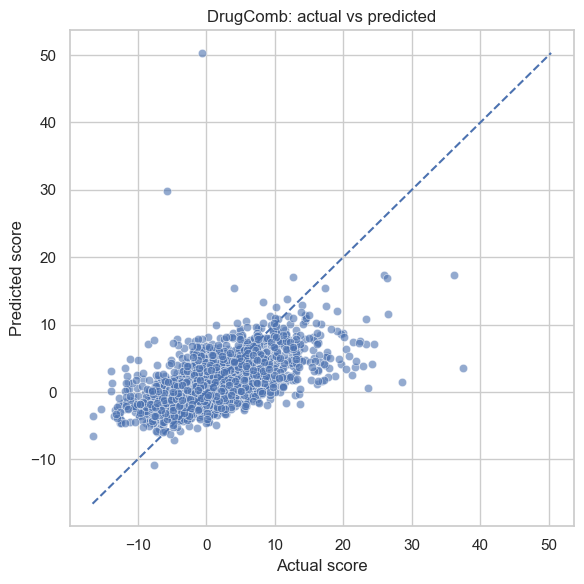

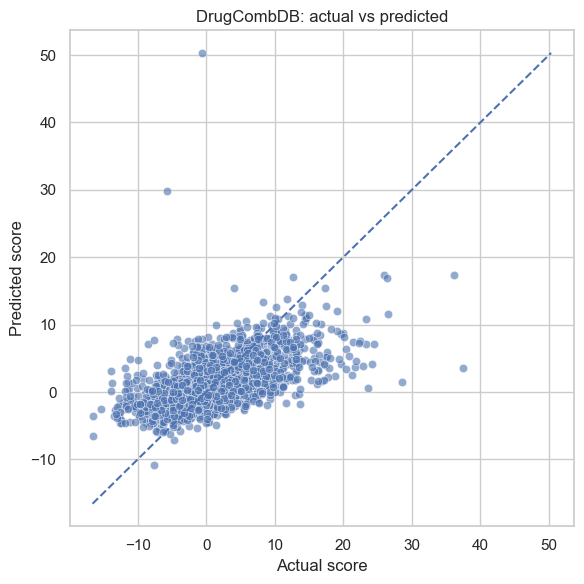

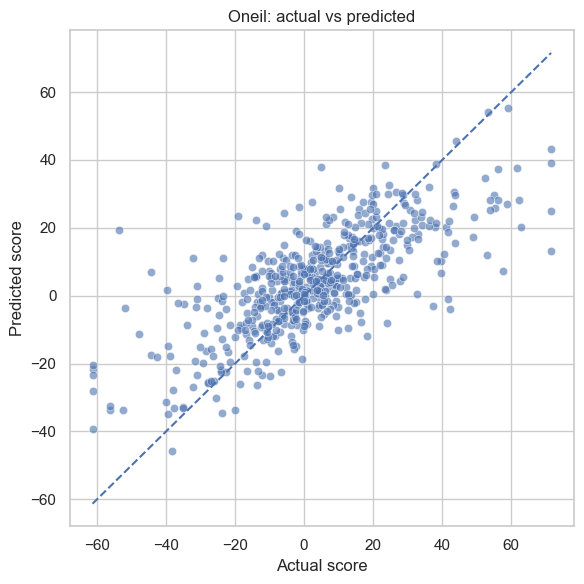

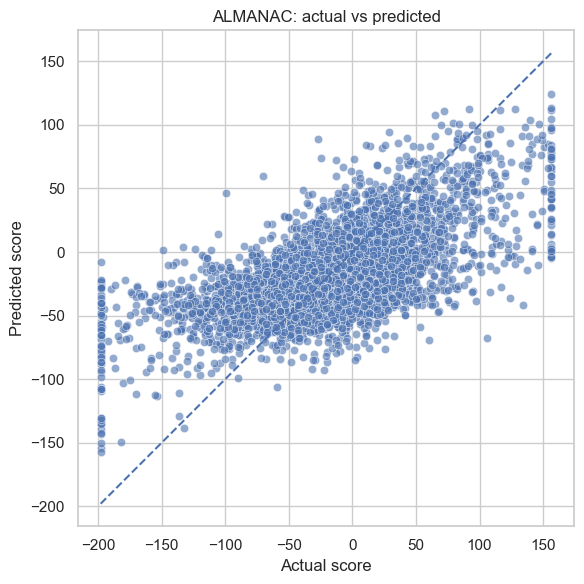

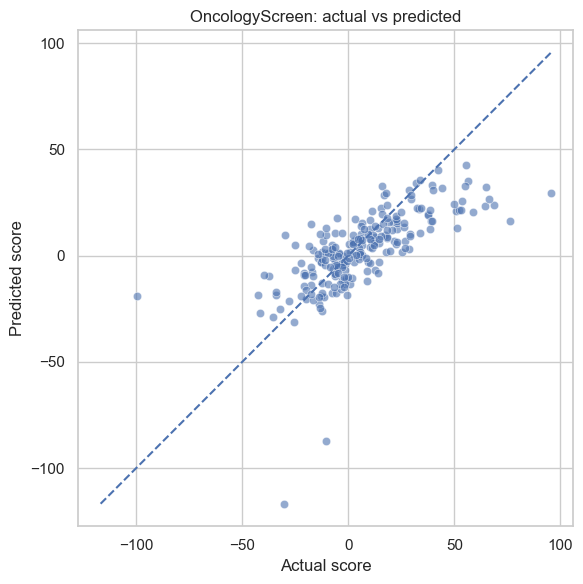

In [72]:
for dataset_name in results["Dataset"]:
    pred_path = os.path.join(OUTPUT_DIR, f"{dataset_name}_test_predictions.csv")
    if not os.path.exists(pred_path):
        continue

    pred = pd.read_csv(pred_path)
    low = min(pred["actual_score"].min(), pred["predicted_score"].min())
    high = max(pred["actual_score"].max(), pred["predicted_score"].max())

    plt.figure(figsize=(6, 6))
    sns.scatterplot(
        data=pred,
        x="actual_score",
        y="predicted_score",
        alpha=0.6
    )
    plt.plot([low, high], [low, high], linestyle="--")
    plt.title(f"{dataset_name}: actual vs predicted")
    plt.xlabel("Actual score")
    plt.ylabel("Predicted score")
    plt.tight_layout()
    plt.savefig(
        os.path.join(OUTPUT_DIR, f"{dataset_name}_actual_vs_predicted.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()